In [2]:
### Loading the required packages
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

### Data Preprocessing & Cleaning

In [3]:
## Reading the data file
df_clv = pd.read_csv('WA_Fn-UseC_-Marketing-Customer-Value-Analysis.csv')
df_clv.shape    # Checking the rows and column

(9134, 24)

In [4]:
df_clv.columns  # Checking the file

Index(['Customer', 'State', 'Customer Lifetime Value', 'Response', 'Coverage',
       'Education', 'Effective To Date', 'EmploymentStatus', 'Gender',
       'Income', 'Location Code', 'Marital Status', 'Monthly Premium Auto',
       'Months Since Last Claim', 'Months Since Policy Inception',
       'Number of Open Complaints', 'Number of Policies', 'Policy Type',
       'Policy', 'Renew Offer Type', 'Sales Channel', 'Total Claim Amount',
       'Vehicle Class', 'Vehicle Size'],
      dtype='object')

In [5]:
# Renaming all the columns for easier data analysis
df_clv.rename(columns = {'Customer': 'customer_id',
                         'State': 'state',
                         'Customer Lifetime Value': 'customer_lifetime_value',
                         'Response': 'response',
                         'Coverage': 'coverage',
                         'Education': 'education',
                         'Effective To Date': 'effective_to_date',
                         'EmploymentStatus' : 'employment_status',
                         'Gender' : 'gender',
                         'Income' : 'income',
                         'Location Code': 'region',
                         'Marital Status' : 'marital_status',
                         'Monthly Premium Auto': 'monthly_premium',
                         'Months Since Last Claim': 'months_since_last_claim',
                         'Months Since Policy Inception' : 'months_since_policy_inception',
                         'Number of Open Complaints': 'no_of_open_complaints',
                         'Number of Policies' : 'no_of_policies',
                         'Policy': 'policy',
                         'Policy Type': 'policy_type',
                         'Renew Offer Type': 'renew_offer_type',
                         'Sales Channel': 'sales_channel',
                         'Total Claim Amount': 'total_claim',
                         'Vehicle Class': 'vehicle_class',
                         'Vehicle Size': 'vehicle_size'}, inplace = True)

# Checking the revised column names
df_clv.columns

Index(['customer_id', 'state', 'customer_lifetime_value', 'response',
       'coverage', 'education', 'effective_to_date', 'employment_status',
       'gender', 'income', 'region', 'marital_status', 'monthly_premium',
       'months_since_last_claim', 'months_since_policy_inception',
       'no_of_open_complaints', 'no_of_policies', 'policy_type', 'policy',
       'renew_offer_type', 'sales_channel', 'total_claim', 'vehicle_class',
       'vehicle_size'],
      dtype='object')

#### Checking for Missed Values

In [6]:
df_clv.isnull().sum()

customer_id                      0
state                            0
customer_lifetime_value          0
response                         0
coverage                         0
education                        0
effective_to_date                0
employment_status                0
gender                           0
income                           0
region                           0
marital_status                   0
monthly_premium                  0
months_since_last_claim          0
months_since_policy_inception    0
no_of_open_complaints            0
no_of_policies                   0
policy_type                      0
policy                           0
renew_offer_type                 0
sales_channel                    0
total_claim                      0
vehicle_class                    0
vehicle_size                     0
dtype: int64

No missing value

#### Checking for Mixed Data Types

In [7]:
mixed_cols = []
for col in df_clv.columns.tolist():
    weird = (df_clv[col].apply(type) != type(df_clv[col].iloc[0])).any()
    if weird: 
        mixed_cols.append(col)

if len(mixed_cols) > 0:
    print("Kolom dengan mixed-type:", mixed_cols)
else:
    print("Tidak ada kolom dengan mixed-type data.")

Kolom dengan mixed-type: ['customer_lifetime_value', 'income', 'monthly_premium', 'months_since_last_claim', 'months_since_policy_inception', 'no_of_open_complaints', 'no_of_policies', 'total_claim']


In [8]:
# Changing column types
# customer_lifetime_value to float
df_clv['customer_lifetime_value'] = pd.to_numeric(df_clv['customer_lifetime_value'], errors='coerce')
df_clv['customer_lifetime_value'] = df_clv['customer_lifetime_value'].astype('float64') 

# Convert effective_to_date 
df_clv['effective_to_date'] = pd.to_datetime(df_clv['effective_to_date'], format='%m/%d/%y', errors='coerce')

# Convert numeric columns 
num_cols = [
    'income', 'monthly_premium', 'months_since_last_claim', 
    'months_since_policy_inception', 'no_of_open_complaints', 
    'no_of_policies'
]

for col in num_cols:
    df_clv[col] = pd.to_numeric(df_clv[col], errors='coerce').astype('int64')
    
# Convert total_claim to float
df_clv['total_claim'] = pd.to_numeric(df_clv['total_claim'], errors='coerce')
df_clv['total_claim'] = df_clv['total_claim'].astype('float64')

In [9]:
print(df_clv.dtypes)

customer_id                              object
state                                    object
customer_lifetime_value                 float64
response                                 object
coverage                                 object
education                                object
effective_to_date                datetime64[ns]
employment_status                        object
gender                                   object
income                                    int64
region                                   object
marital_status                           object
monthly_premium                           int64
months_since_last_claim                   int64
months_since_policy_inception             int64
no_of_open_complaints                     int64
no_of_policies                            int64
policy_type                              object
policy                                   object
renew_offer_type                         object
sales_channel                           

#### Checking for Duplicates

In [10]:
print(df_clv.drop_duplicates(inplace=True))

None


### Descriptive Statistics

In [11]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Definisi variabel numerik dan kategorik (mengecualikan customer_id & effective_to_date)
numeric_vars = [
    'customer_lifetime_value',
    'income',
    'monthly_premium',
    'total_claim',
    'months_since_policy_inception',
    'months_since_last_claim',
    'no_of_policies',
    'no_of_open_complaints'
]

categorical_vars = [
    'state', 'response', 'coverage', 'education', 'employment_status',
    'gender', 'region', 'marital_status', 'policy_type', 'policy',
    'renew_offer_type', 'sales_channel', 'vehicle_class', 'vehicle_size'
]

# 1. Ringkasan rentang waktu polis (effective_to_date)
print("Rentang Periode Data")
print(f"Periode Effective To Date : {df_clv['effective_to_date'].min().strftime('%Y-%m-%d')} s.d. {df_clv['effective_to_date'].max().strftime('%Y-%m-%d')}")
print(f"Total Observasi           : {len(df_clv):,} nasabah\n")

# 2. Statistika deskriptif lengkap untuk variabel numerik
def descriptive_numeric(df, cols):
    stats_list = []
    for col in cols:
        s = df[col].dropna()
        q1, med, q3 = np.percentile(s, [25, 50, 75])
        stats_list.append({
            'Variabel': col,
            'N': len(s),
            'Mean': round(s.mean(), 2),
            'Std. Dev': round(s.std(), 2),
            'Min': round(s.min(), 2),
            'Q1 (25%)': round(q1, 2),
            'Median': round(med, 2),
            'Q3 (75%)': round(q3, 2),
            'IQR': round(q3 - q1, 2),
            'Max': round(s.max(), 2),
            'Skewness': round(skew(s), 3),
            'Kurtosis': round(kurtosis(s), 3)
        })
    return pd.DataFrame(stats_list)

df_desc_num = descriptive_numeric(df_clv, numeric_vars)
print("Statistika Deskriptif Variabel Numerik")
display(df_desc_num)

Rentang Periode Data
Periode Effective To Date : 2011-01-01 s.d. 2011-02-28
Total Observasi           : 9,134 nasabah

Statistika Deskriptif Variabel Numerik


,Variabel,N,Mean,Std. Dev,Min,Q1 (25%),Median,Q3 (75%),IQR,Max,Skewness,Kurtosis
0,customer_lifetime_value,9134,8004.94,6870.97,1898.01,3994.25,5780.18,8962.17,4967.92,83325.38,3.032,13.815
1,income,9134,37657.38,30379.90,0.00,0.00,33889.50,62320.00,62320.00,99981.00,0.287,-1.094
2,monthly_premium,9134,93.22,34.41,61.00,68.00,83.00,109.00,41.00,298.00,2.123,6.190
3,total_claim,9134,434.09,290.50,0.10,272.26,383.95,547.51,275.26,2893.24,1.715,5.975
4,months_since_policy_inception,9134,48.06,27.91,0.00,24.00,48.00,71.00,47.00,99.00,0.040,-1.133
5,months_since_last_claim,9134,15.10,10.07,0.00,6.00,14.00,23.00,17.00,35.00,0.279,-1.074
6,no_of_policies,9134,2.97,2.39,1.00,1.00,2.00,4.00,3.00,9.00,1.253,0.362
7,no_of_open_complaints,9134,0.38,0.91,0.00,0.00,0.00,0.00,0.00,5.00,2.783,7.744


In [12]:
# 3. Ringkasan & distribusi frekuensi variabel kategorik
def descriptive_categorical(df, cols):
    summary_list = []
    n = len(df)
    for col in cols:
        vc = df[col].value_counts(dropna=False)
        top_cat = vc.index[0]
        top_freq = vc.iloc[0]
        top_pct = top_freq / n * 100
        summary_list.append({
            'Variabel': col,
            'Jumlah Kategori': df[col].nunique(),
            'Modus': top_cat,
            'Frekuensi Modus': top_freq,
            'Proporsi Modus (%)': round(top_pct, 2)
        })
    return pd.DataFrame(summary_list)

df_desc_cat = descriptive_categorical(df_clv, categorical_vars)
print("Ringkasan Statistika Deskriptif Variabel Kategorik")
display(df_desc_cat)

print("\nTabel Frekuensi & Proporsi Tiap Variabel Kategorik")
for col in categorical_vars:
    freq = df_clv[col].value_counts()
    pct = (df_clv[col].value_counts(normalize=True) * 100).round(2)
    dist_df = pd.DataFrame({'Frekuensi': freq, 'Persentase (%)': pct})
    display(dist_df)

Ringkasan Statistika Deskriptif Variabel Kategorik


,Variabel,Jumlah Kategori,Modus,Frekuensi Modus,Proporsi Modus (%)
0,state,5,California,3150,34.49
1,response,2,No,7826,85.68
2,coverage,3,Basic,5568,60.96
3,education,5,Bachelor,2748,30.09
4,employment_status,5,Employed,5698,62.38
5,gender,2,F,4658,51.00
6,region,3,Suburban,5779,63.27
7,marital_status,3,Married,5298,58.00
8,policy_type,3,Personal Auto,6788,74.32
9,policy,9,Personal L3,3426,37.51



Tabel Frekuensi & Proporsi Tiap Variabel Kategorik


,Frekuensi,Persentase (%)
state,,
California,3150,34.49
Oregon,2601,28.48
Arizona,1703,18.64
Nevada,882,9.66
Washington,798,8.74


,Frekuensi,Persentase (%)
response,,
No,7826,85.68
Yes,1308,14.32


,Frekuensi,Persentase (%)
coverage,,
Basic,5568,60.96
Extended,2742,30.02
Premium,824,9.02


... (7 outputs left out)

,Frekuensi,Persentase (%)
renew_offer_type,,
Offer1,3752,41.08
Offer2,2926,32.03
Offer3,1432,15.68
Offer4,1024,11.21


,Frekuensi,Persentase (%)
sales_channel,,
Agent,3477,38.07
Branch,2567,28.10
Call Center,1765,19.32
Web,1325,14.51


,Frekuensi,Persentase (%)
vehicle_class,,
Four-Door Car,4621,50.59
Two-Door Car,1886,20.65
SUV,1796,19.66
Sports Car,484,5.30
Luxury SUV,184,2.01
Luxury Car,163,1.78


,Frekuensi,Persentase (%)
vehicle_size,,
Medsize,6424,70.33
Small,1764,19.31
Large,946,10.36


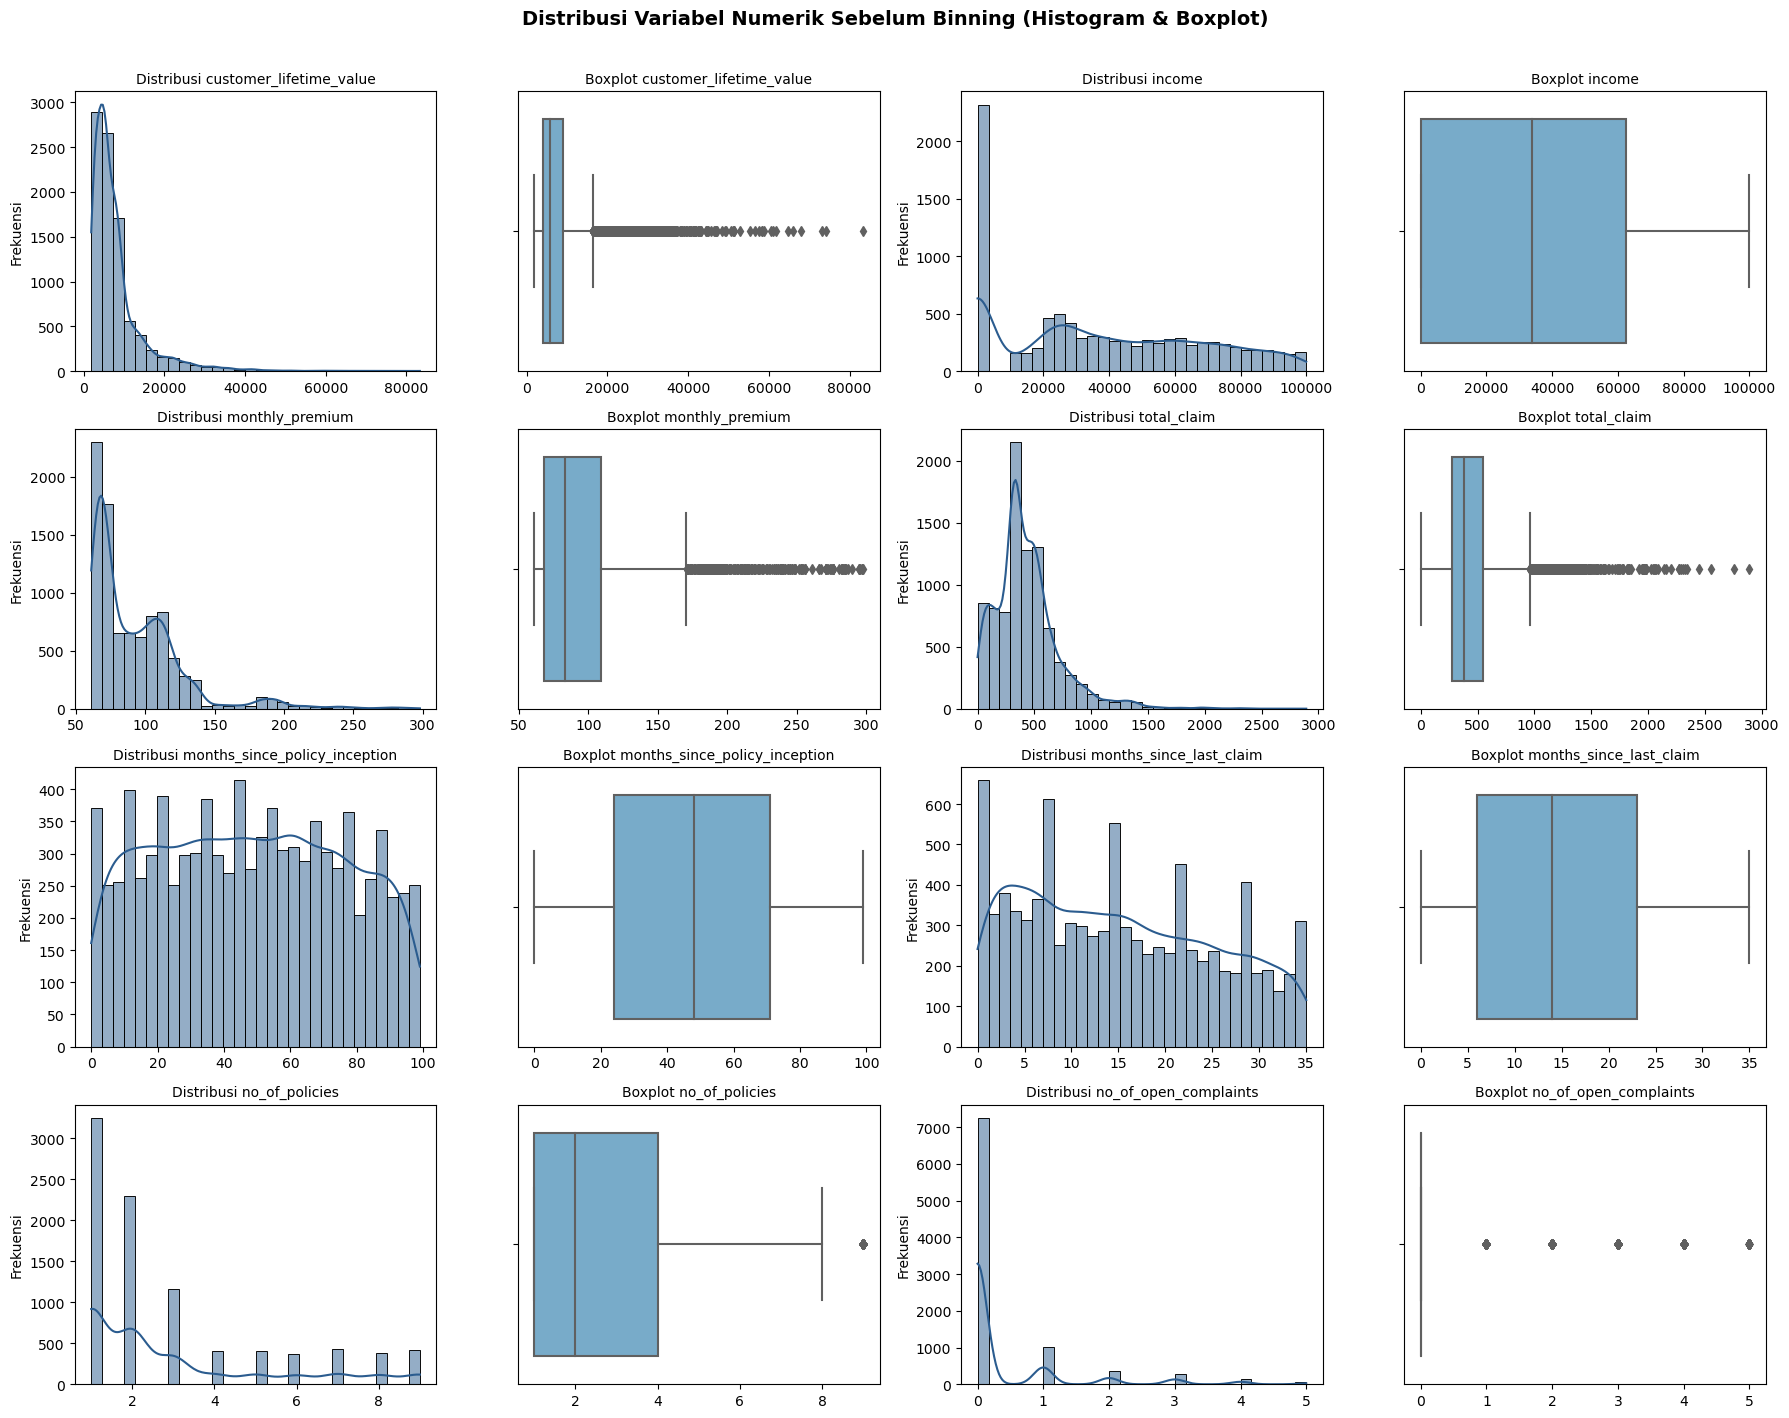

In [13]:
# 4. Visualisasi distribusi & outlier variabel numerik sebelum binning
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 14))
fig.suptitle('Distribusi Variabel Numerik Sebelum Binning (Histogram & Boxplot)', fontsize=14, fontweight='bold', y=1.01)

for idx, col in enumerate(numeric_vars):
    row = idx // 2
    col_hist = (idx % 2) * 2
    col_box = col_hist + 1
    
    # Histogram + KDE
    sns.histplot(df_clv[col], kde=True, ax=axes[row, col_hist], color='#2b5c8f', bins=30)
    axes[row, col_hist].set_title(f'Distribusi {col}', fontsize=10)
    axes[row, col_hist].set_xlabel('')
    axes[row, col_hist].set_ylabel('Frekuensi')
    
    # Boxplot
    sns.boxplot(x=df_clv[col], ax=axes[row, col_box], color='#6baed6')
    axes[row, col_box].set_title(f'Boxplot {col}', fontsize=10)
    axes[row, col_box].set_xlabel('')

plt.tight_layout()
plt.show()

### Data Binning

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, chi2_contingency

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Daftar 8 variabel numerik pada dataset IBM Watson
numeric_vars = [
    'customer_lifetime_value',
    'income',
    'monthly_premium',
    'total_claim',
    'months_since_policy_inception',
    'months_since_last_claim',
    'no_of_policies',
    'no_of_open_complaints'
]

def diagnose_distributions(df, cols):
    records = []
    n = len(df)
    for col in cols:
        s = df[col].dropna()
        n_unique = s.nunique()
        zero_pct = (s == 0).sum() / n * 100
        mode_val = s.mode().iloc[0]
        mode_pct = (s == mode_val).sum() / n * 100
        sk = skew(s)
        kt = kurtosis(s)
        q25, q50, q75 = np.percentile(s, [25, 50, 75])
        
        # Klasifikasi otomatis pola distribusi & rekomendasi metode binning
        if zero_pct > 50 or (n_unique <= 10 and mode_pct > 50):
            dist_type = "Extreme Zero / Single-Value Concentrated"
            rec_method = "Binary Domain Rule (0 vs >= 1)"
        elif n_unique <= 15:
            dist_type = "Discrete Count (Right-Skewed)"
            rec_method = "Domain Rule-Based (1, 2, >= 3)"
        elif zero_pct >= 15:
            dist_type = "Zero-Inflated Continuous"
            rec_method = "Hybrid Rule (0 dipisah) + Tertil (> 0)"
        elif abs(sk) > 0.75:
            dist_type = "Right-Skewed Continuous"
            rec_method = "Equal-Frequency Quartiles (pd.qcut, q=4)"
        else:
            dist_type = "Near-Uniform / Mildly Skewed"
            rec_method = "Equal-Frequency Quantiles (pd.qcut, q=3/4)"
            
        records.append({
            'Variabel': col,
            'Unique': n_unique,
            'Min': round(s.min(), 2),
            'Q1 (25%)': round(q25, 2),
            'Median': round(q50, 2),
            'Q3 (75%)': round(q75, 2),
            'Max': round(s.max(), 2),
            'Skewness': round(sk, 3),
            'Kurtosis': round(kt, 3),
            '% Zero': round(zero_pct, 2),
            '% Modus': round(mode_pct, 2),
            'Karakteristik Distribusi': dist_type,
            'Metode Binning Disarankan': rec_method
        })
    return pd.DataFrame(records)

df_diag = diagnose_distributions(df_clv, numeric_vars)
display(df_diag)

,Variabel,Unique,Min,Q1 (25%),Median,Q3 (75%),Max,Skewness,Kurtosis,% Zero,% Modus,Karakteristik Distribusi,Metode Binning Disarankan
0,customer_lifetime_value,8041,1898.01,3994.25,5780.18,8962.17,83325.38,3.032,13.815,0.00,0.07,Right-Skewed Continuous,"Equal-Frequency Quartiles (pd.qcut, q=4)"
1,income,5694,0.00,0.00,33889.50,62320.00,99981.00,0.287,-1.094,25.37,25.37,Zero-Inflated Continuous,Hybrid Rule (0 dipisah) + Tertil (> 0)
2,monthly_premium,202,61.00,68.00,83.00,109.00,298.00,2.123,6.190,0.00,3.81,Right-Skewed Continuous,"Equal-Frequency Quartiles (pd.qcut, q=4)"
3,total_claim,5106,0.10,272.26,383.95,547.51,2893.24,1.715,5.975,0.00,1.27,Right-Skewed Continuous,"Equal-Frequency Quartiles (pd.qcut, q=4)"
4,months_since_policy_inception,100,0.00,24.00,48.00,71.00,99.00,0.040,-1.133,0.91,1.55,Near-Uniform / Mildly Skewed,"Equal-Frequency Quantiles (pd.qcut, q=3/4)"
5,months_since_last_claim,36,0.00,6.00,14.00,23.00,35.00,0.279,-1.074,3.44,4.17,Near-Uniform / Mildly Skewed,"Equal-Frequency Quantiles (pd.qcut, q=3/4)"
6,no_of_policies,9,1.00,1.00,2.00,4.00,9.00,1.253,0.362,0.00,35.59,Discrete Count (Right-Skewed),"Domain Rule-Based (1, 2, >= 3)"
7,no_of_open_complaints,6,0.00,0.00,0.00,0.00,5.00,2.783,7.744,79.40,79.40,Extreme Zero / Single-Value Concentrated,Binary Domain Rule (0 vs >= 1)


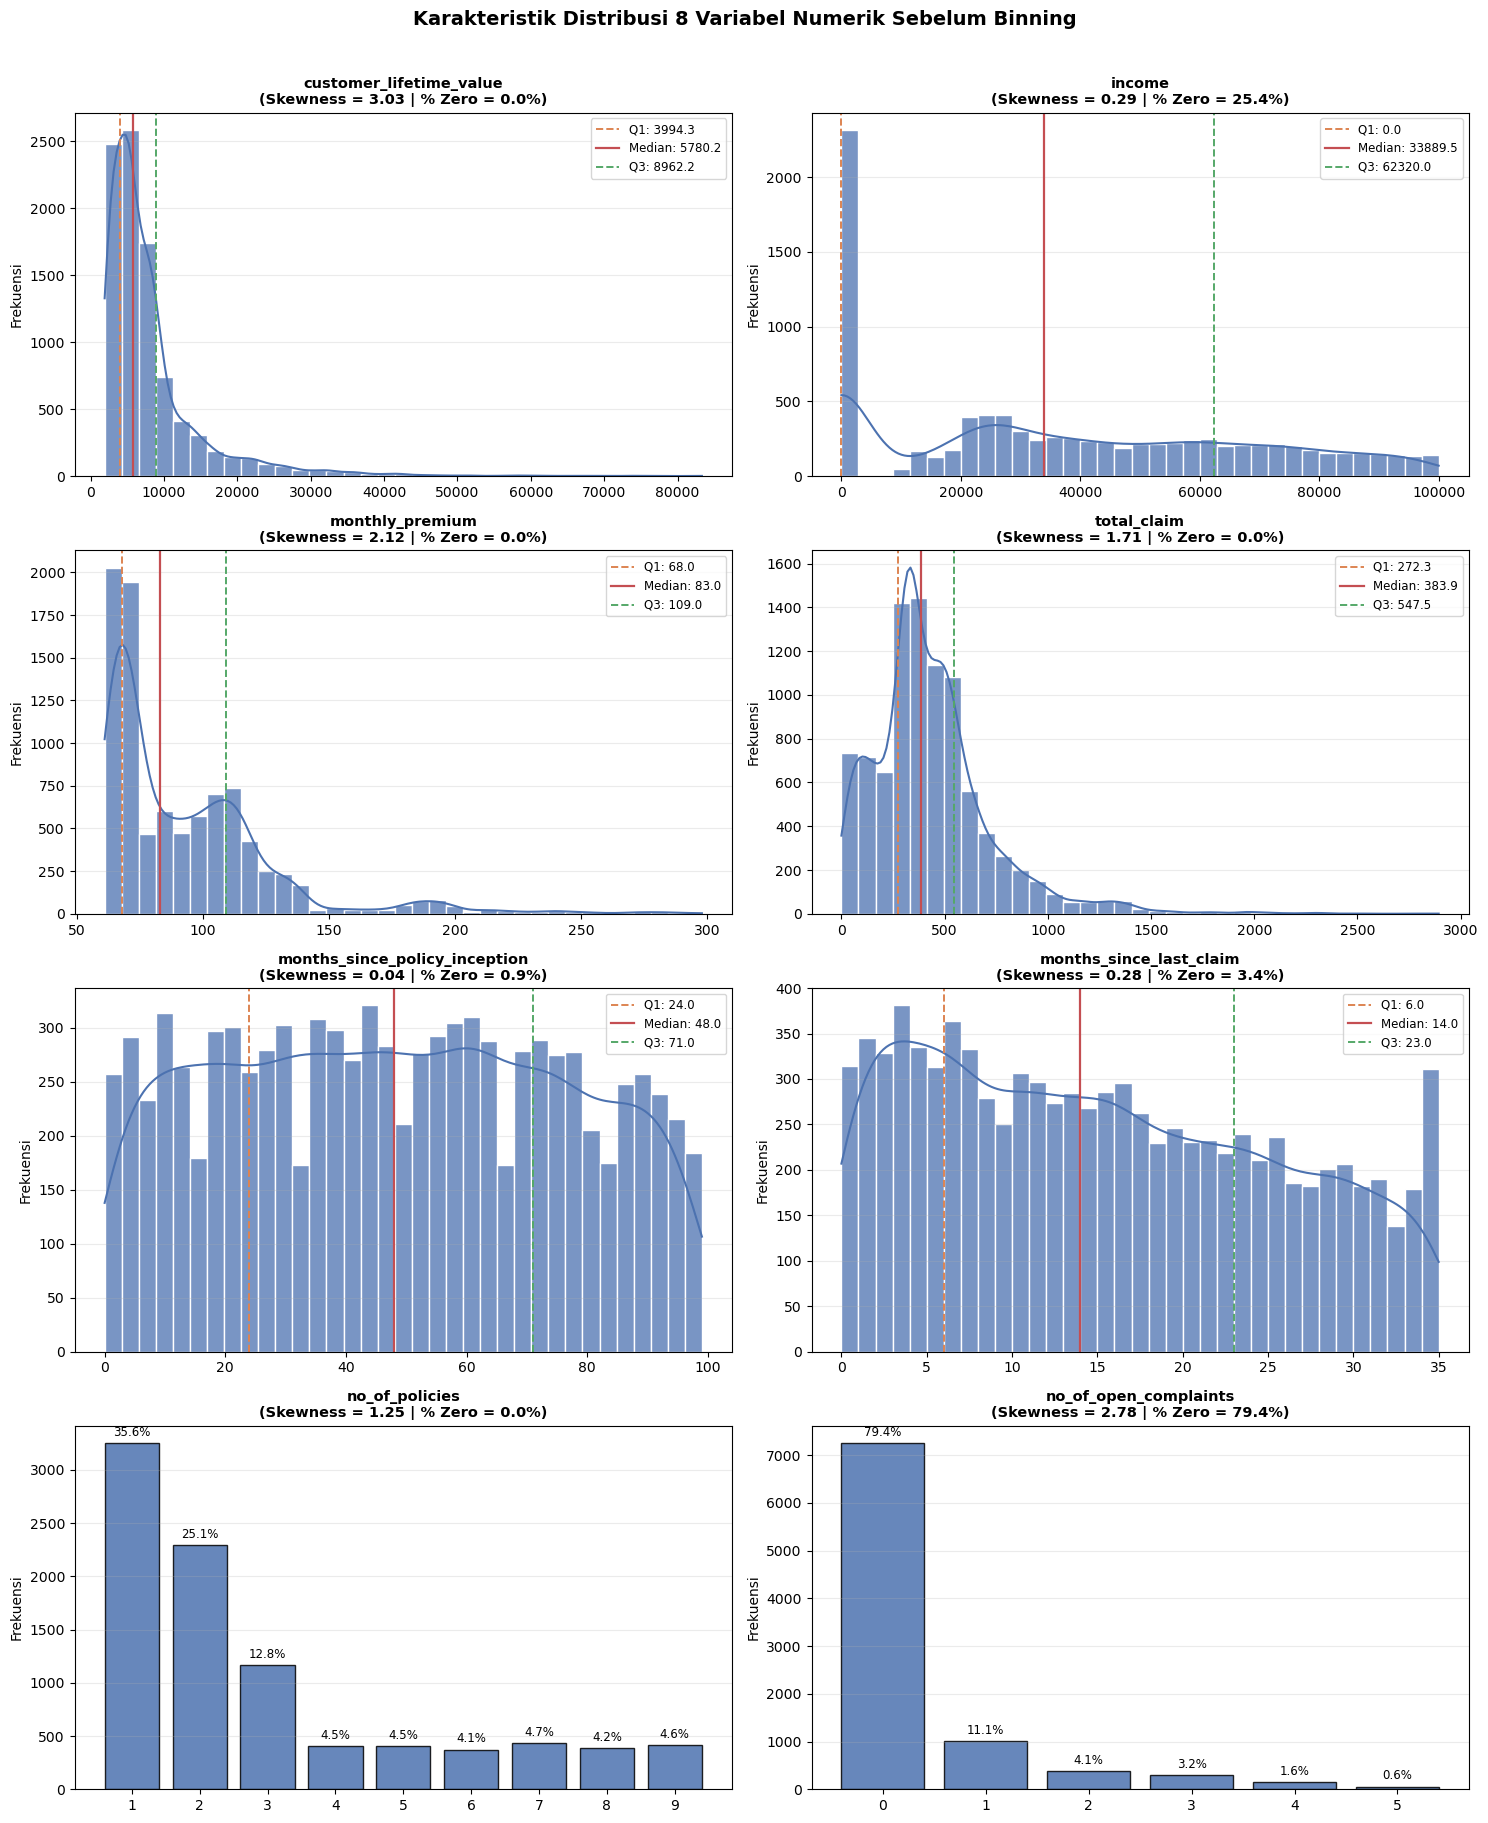

In [15]:
# Visualisasi Distribusi Empiris & Garis Kuartil untuk Setiap Variabel Numerik
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for idx, col in enumerate(numeric_vars):
    ax = axes[idx]
    s = df_clv[col]
    
    if s.nunique() <= 15:
        # Bar chart proporsi untuk variabel diskret dengan nilai unik sedikit
        counts = s.value_counts().sort_index()
        bars = ax.bar(counts.index.astype(str), counts.values, color='#4C72B0', edgecolor='black', alpha=0.85)
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h/len(s)*100:.1f}%",
                        xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=8.5)
        ax.set_ylabel("Frekuensi")
    else:
        # Histogram + KDE + Garis Kuartil untuk variabel kontinu / rentang lebar
        sns.histplot(s, bins=35, kde=True, ax=ax, color='#4C72B0', edgecolor='white', alpha=0.75)
        q25, q50, q75 = np.percentile(s, [25, 50, 75])
        ax.axvline(q25, color='#DD8452', linestyle='--', linewidth=1.4, label=f'Q1: {q25:.1f}')
        ax.axvline(q50, color='#C44E52', linestyle='-', linewidth=1.6, label=f'Median: {q50:.1f}')
        ax.axvline(q75, color='#55A868', linestyle='--', linewidth=1.4, label=f'Q3: {q75:.1f}')
        ax.legend(fontsize=8.5, loc='upper right')
        ax.set_ylabel("Frekuensi")
        
    sk_val = skew(s)
    zero_val = (s == 0).mean() * 100
    ax.set_title(f"{col}\n(Skewness = {sk_val:.2f} | % Zero = {zero_val:.1f}%)", fontsize=10.5, fontweight='bold')
    ax.set_xlabel("")
    ax.grid(axis='y', alpha=0.25)

plt.suptitle("Karakteristik Distribusi 8 Variabel Numerik Sebelum Binning", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [16]:
# Copy dataframe untuk menyimpan hasil binning tanpa mengubah data mentah
df_binned = df_clv.copy()
bin_boundaries = {}

# 1. Hybrid Rule + Tertil untuk 'income' (memisahkan nilai 0 terlebih dahulu)
income_pos = df_binned.loc[df_binned['income'] > 0, 'income']
_, inc_bins_pos = pd.qcut(income_pos, q=3, retbins=True)
inc_full_bins = [-1, 0, inc_bins_pos[1], inc_bins_pos[2], df_binned['income'].max()]
inc_labels = ['Nol (0)', 'Rendah', 'Menengah', 'Tinggi']
df_binned['income_cat'] = pd.cut(df_binned['income'], bins=inc_full_bins, labels=inc_labels)
bin_boundaries['income_cat'] = (
    f"Nol: 0 | Rendah: (0, {inc_bins_pos[1]:.0f}] | "
    f"Menengah: ({inc_bins_pos[1]:.0f}, {inc_bins_pos[2]:.0f}] | Tinggi: > {inc_bins_pos[2]:.0f}"
)

# 2. Equal-Frequency Quartiles (q=4) untuk variabel kontinu right-skewed & tenurial
q4_specs = {
    'customer_lifetime_value': ('clv_cat', ['Q1 (Rendah)', 'Q2 (Menengah)', 'Q3 (Tinggi)', 'Q4 (Sangat Tinggi)']),
    'monthly_premium': ('monthly_premium_cat', ['Q1 (Rendah)', 'Q2 (Menengah)', 'Q3 (Tinggi)', 'Q4 (Sangat Tinggi)']),
    'total_claim': ('total_claim_cat', ['Q1 (Kecil)', 'Q2 (Sedang)', 'Q3 (Besar)', 'Q4 (Sangat Besar)']),
    'months_since_policy_inception': ('tenure_cat', ['Baru', 'Menengah', 'Lama', 'Sangat Lama'])
}

for raw_col, (cat_col, labels) in q4_specs.items():
    df_binned[cat_col], intervals = pd.qcut(df_binned[raw_col], q=4, labels=labels, retbins=True)
    bin_boundaries[cat_col] = " | ".join(
        [f"{labels[i]}: [{intervals[i]:.2f}, {intervals[i+1]:.2f}]" for i in range(4)]
    )

# 3. Equal-Frequency Tertiles (q=3) untuk 'months_since_last_claim'
claim_time_labels = ['Baru Klaim', 'Sedang', 'Lama Tidak Klaim']
df_binned['last_claim_cat'], lc_intervals = pd.qcut(
    df_binned['months_since_last_claim'], q=3, labels=claim_time_labels, retbins=True
)
bin_boundaries['last_claim_cat'] = " | ".join(
    [f"{claim_time_labels[i]}: [{lc_intervals[i]:.0f}, {lc_intervals[i+1]:.0f}]" for i in range(3)]
)

# 4. Domain Rule-Based untuk 'no_of_policies'
policy_bins = [0, 1, 2, df_binned['no_of_policies'].max()]
policy_labels = ['1 Polis (Single)', '2 Polis (Dual)', '>= 3 Polis (Multi)']
df_binned['no_of_policies_cat'] = pd.cut(df_binned['no_of_policies'], bins=policy_bins, labels=policy_labels)
bin_boundaries['no_of_policies_cat'] = "1 Polis: 1 | 2 Polis: 2 | >= 3 Polis: 3-9"

# 5. Binary Domain Rule untuk 'no_of_open_complaints'
comp_bins = [-1, 0, df_binned['no_of_open_complaints'].max()]
comp_labels = ['Tidak Ada Keluhan', 'Ada Keluhan']
df_binned['complaints_cat'] = pd.cut(df_binned['no_of_open_complaints'], bins=comp_bins, labels=comp_labels)
bin_boundaries['complaints_cat'] = "Tidak Ada Keluhan: 0 | Ada Keluhan: >= 1"

# Tampilkan ringkasan batas interval setiap variabel hasil binning
print("Ringkasan Batas Interval Hasil Binning")
for k, v in bin_boundaries.items():
    print(f"- {k:<22}: {v}")

Ringkasan Batas Interval Hasil Binning
- income_cat            : Nol: 0 | Rendah: (0, 34226] | Menengah: (34226, 62445] | Tinggi: > 62445
- clv_cat               : Q1 (Rendah): [1898.01, 3994.25] | Q2 (Menengah): [3994.25, 5780.18] | Q3 (Tinggi): [5780.18, 8962.17] | Q4 (Sangat Tinggi): [8962.17, 83325.38]
- monthly_premium_cat   : Q1 (Rendah): [61.00, 68.00] | Q2 (Menengah): [68.00, 83.00] | Q3 (Tinggi): [83.00, 109.00] | Q4 (Sangat Tinggi): [109.00, 298.00]
- total_claim_cat       : Q1 (Kecil): [0.10, 272.26] | Q2 (Sedang): [272.26, 383.95] | Q3 (Besar): [383.95, 547.51] | Q4 (Sangat Besar): [547.51, 2893.24]
- tenure_cat            : Baru: [0.00, 24.00] | Menengah: [24.00, 48.00] | Lama: [48.00, 71.00] | Sangat Lama: [71.00, 99.00]
- last_claim_cat        : Baru Klaim: [0, 9] | Sedang: [9, 20] | Lama Tidak Klaim: [20, 35]
- no_of_policies_cat    : 1 Polis: 1 | 2 Polis: 2 | >= 3 Polis: 3-9
- complaints_cat        : Tidak Ada Keluhan: 0 | Ada Keluhan: >= 1


#### Validasi Hasil Binning untuk SCA & MFACT

Sebelum variabel kategorikal hasil *binning* dimasukkan ke dalam **SCA** dan **MFACT**, dilakukan pemeriksaan tiga kriteria validitas matematis:
1. **Proporsionalitas Massa Marginal ($r_i$):** Setiap kategori memiliki proporsi minimal $\ge 5\%$ ($0{,}05$) dari total sampel ($N = 9.134$) agar bobot $D_r^{-1/2}$ pada SCA tidak menghasilkan *extreme leverage*.
2. **Syarat Frekuensi Harapan ($E_{ij}$):** Minimal 80% sel tabel kontingensi memiliki $E_{ij} \ge 5$ dan tidak ada sel dengan $E_{ij} < 1$.
3. **Signifikansi Asosiasi ($\chi^2$ & Cramér's $V$):** Menguji keterkaitan bivariat antara masing-masing variabel hasil *binning* terhadap variabel acuan produk asuransi (`policy_type` dan `coverage`).

1. Pemeriksaan Massa Marginal (r_i) Tiap Kategori Hasil Binning
income_cat             | Min r_i =  24.9% [VALID (>= 5%)] -> Nol (0): 25.4%, Rendah: 24.9%, Menengah: 24.9%, Tinggi: 24.9%
clv_cat                | Min r_i =  25.0% [VALID (>= 5%)] -> Q1 (Rendah): 25.0%, Q2 (Menengah): 25.0%, Q4 (Sangat Tinggi): 25.0%, Q3 (Tinggi): 25.0%
monthly_premium_cat    | Min r_i =  24.4% [VALID (>= 5%)] -> Q2 (Menengah): 25.6%, Q1 (Rendah): 25.2%, Q3 (Tinggi): 24.8%, Q4 (Sangat Tinggi): 24.4%
total_claim_cat        | Min r_i =  25.0% [VALID (>= 5%)] -> Q1 (Kecil): 25.0%, Q4 (Sangat Besar): 25.0%, Q2 (Sedang): 25.0%, Q3 (Besar): 25.0%
tenure_cat             | Min r_i =  24.5% [VALID (>= 5%)] -> Menengah: 25.5%, Baru: 25.3%, Sangat Lama: 24.8%, Lama: 24.5%
last_claim_cat         | Min r_i =  31.9% [VALID (>= 5%)] -> Baru Klaim: 35.5%, Sedang: 32.6%, Lama Tidak Klaim: 31.9%
no_of_policies_cat     | Min r_i =  25.1% [VALID (>= 5%)] -> >= 3 Polis (Multi): 39.3%, 1 Polis (Single): 35.6%, 2 Polis (Dual): 

,Variabel Acuan,Variabel Binned,Dimensi Tabel,Min E_ij,% Sel E_ij >= 5,Chi-Square,dof,p-value,Cramer's V,Signifikan (alpha=0.05)
0,policy_type,customer_id,9134x3,0.04,0.0,18268.00,18266,4.9443e-01,1.0000,Tidak
1,policy_type,state,5x3,33.02,100.0,17.25,8,2.7598e-02,0.0307,Ya
2,policy_type,customer_lifetime_value,8041x3,0.04,0.0,15906.53,16080,8.3325e-01,0.9331,Tidak
3,policy_type,response,2x3,54.13,100.0,1.73,2,4.2092e-01,0.0138,Tidak
4,policy_type,education,5x3,14.15,100.0,7.77,8,4.5630e-01,0.0206,Tidak
...,...,...,...,...,...,...,...,...,...,...
110,no_of_policies_cat,renew_offer_type,4x3,257.18,100.0,187.70,6,7.8341e-38,0.1014,Ya
111,no_of_policies_cat,sales_channel,4x3,332.77,100.0,7.64,6,2.6545e-01,0.0205,Tidak
112,no_of_policies_cat,total_claim,5106x3,0.25,1.3,11412.83,10210,2.4805e-16,0.7904,Ya
113,no_of_policies_cat,vehicle_class,6x3,40.94,100.0,8.06,10,6.2266e-01,0.0210,Tidak



3. Matriks Korelasi Kategorikal (Cramer's V)


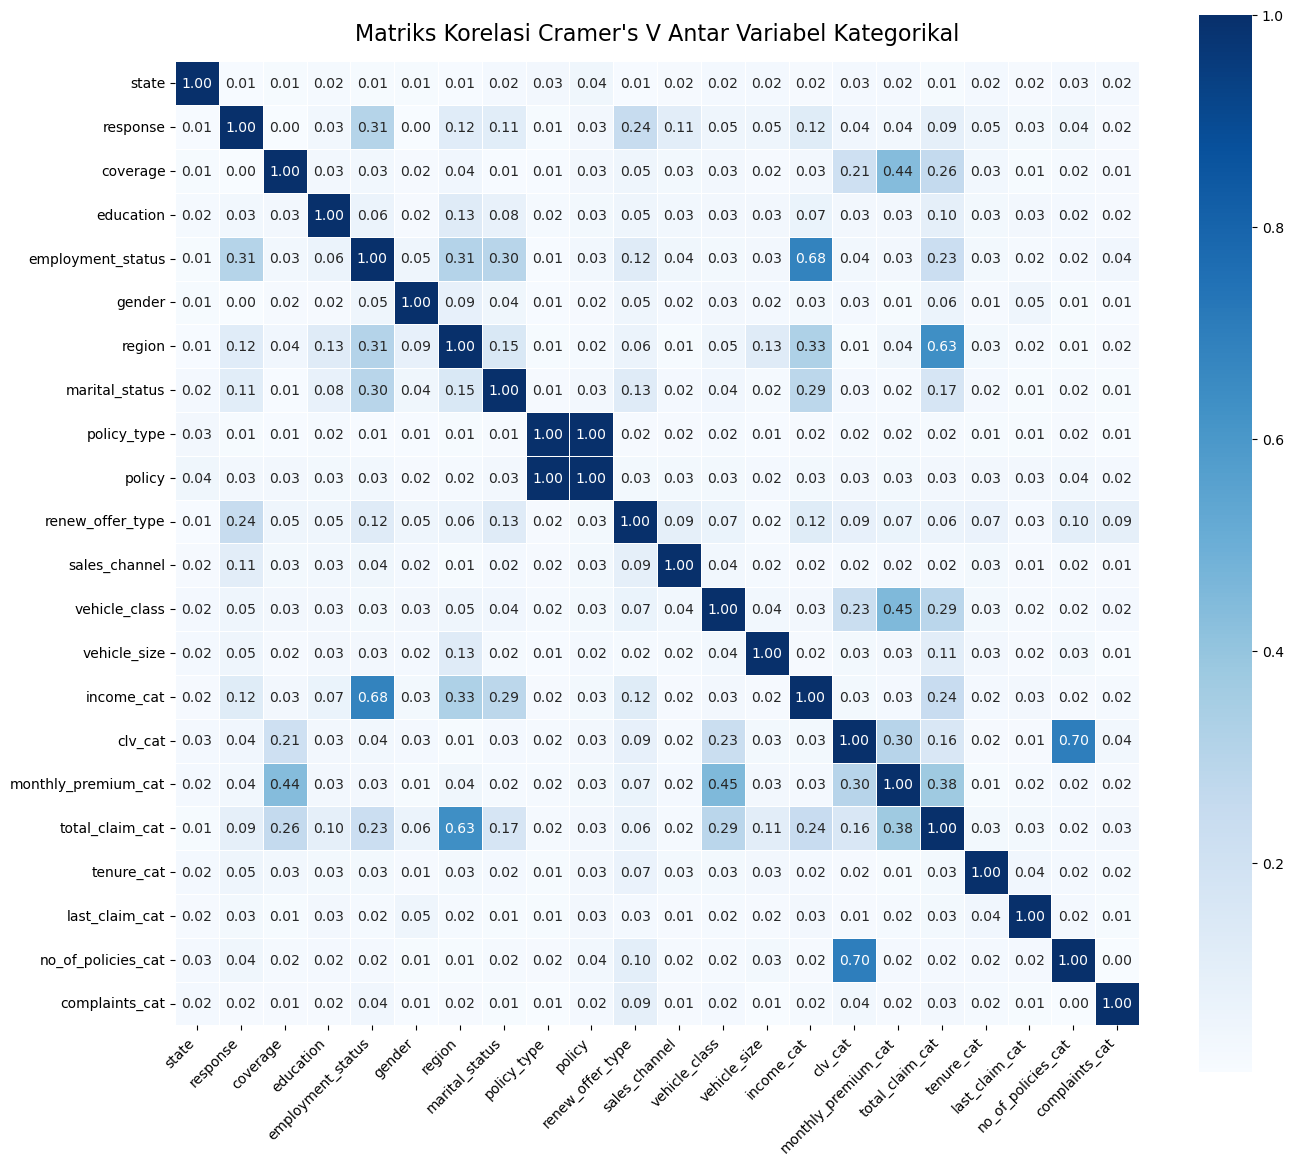

In [25]:
import os
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

binned_cols = [
    'income_cat', 'clv_cat', 'monthly_premium_cat', 'total_claim_cat',
    'tenure_cat', 'last_claim_cat', 'no_of_policies_cat', 'complaints_cat'
]
cols = [
    'customer_id', 'state', 'customer_lifetime_value', 'response',
    'education', 'effective_to_date', 'employment_status',
    'gender', 'income', 'region', 'marital_status', 'monthly_premium',
    'months_since_last_claim', 'months_since_policy_inception',
    'no_of_open_complaints', 'no_of_policies', 'policy_type', 'policy',
    'renew_offer_type', 'sales_channel', 'total_claim', 'vehicle_class',
    'vehicle_size'
]

# 1. Cek Proporsi Massa Marginal (r_i)
print("1. Pemeriksaan Massa Marginal (r_i) Tiap Kategori Hasil Binning")
for col in binned_cols:
    props = df_binned[col].value_counts(normalize=True) * 100
    min_prop = props.min()
    status = "VALID (>= 5%)" if min_prop >= 5.0 else "PERINGATAN (< 5%)"
    prop_str = ", ".join([f"{idx}: {val:.1f}%" for idx, val in props.items()])
    print(f"{col:<22} | Min r_i = {min_prop:5.1f}% [{status}] -> {prop_str}")

# 2. Uji Validitas Tabel Kontingensi & Signifikansi Chi-Square terhadap Variabel Polis
target_polis_vars = ['policy_type', 'coverage', 'policy', 'monthly_premium_cat', 'no_of_policies_cat'] 
val_records = []

for target in target_polis_vars:
    for col in cols:
        ct = pd.crosstab(df_binned[col], df_binned[target])
        chi2_stat, p_val, dof, expected = chi2_contingency(ct)
        n_total = ct.values.sum()
        min_dim = min(ct.shape[0] - 1, ct.shape[1] - 1)
        cramers_v = np.sqrt(chi2_stat / (n_total * min_dim)) if min_dim > 0 and n_total > 0 else 0.0
        pct_e_ge_5 = (expected >= 5).mean() * 100
        min_e = expected.min()
        
        val_records.append({
            'Variabel Acuan': target,
            'Variabel Binned': col,
            'Dimensi Tabel': f"{ct.shape[0]}x{ct.shape[1]}",
            'Min E_ij': round(min_e, 2),
            '% Sel E_ij >= 5': round(pct_e_ge_5, 1),
            'Chi-Square': round(chi2_stat, 2),
            'dof': dof,
            'p-value': f"{p_val:.4e}",
            "Cramer's V": round(cramers_v, 4),
            'Signifikan (alpha=0.05)': 'Ya' if p_val < 0.05 else 'Tidak'
        })

df_val_sca = pd.DataFrame(val_records)
print("\n2. Validasi Tabel Kontingensi & Uji Chi-Square Untuk SCA")
display(df_val_sca)

# 3. Matriks Korelasi Kategorikal (Cramer's V) Antar Seluruh Variabel Kategorikal
existing_cat_cols = [
    'state', 'response', 'coverage', 'education', 'employment_status',
    'gender', 'region', 'marital_status', 'policy_type', 'policy',
    'renew_offer_type', 'sales_channel', 'vehicle_class', 'vehicle_size'
]

def calculate_cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.size == 0:
        return 0.0
    chi2_stat, _, _, _ = chi2_contingency(ct)
    n_total = ct.values.sum()
    min_dim = min(ct.shape[0] - 1, ct.shape[1] - 1)
    if min_dim == 0 or n_total == 0:
        return 0.0
    return np.sqrt(chi2_stat / (n_total * min_dim))

all_cat_cols = existing_cat_cols + binned_cols
cramers_matrix = pd.DataFrame(index=all_cat_cols, columns=all_cat_cols, dtype=float)

for col1 in all_cat_cols:
    for col2 in all_cat_cols:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0
        else:
            cramers_matrix.loc[col1, col2] = calculate_cramers_v(df_binned[col1], df_binned[col2])

print("\n3. Matriks Korelasi Kategorikal (Cramer's V)")

# Visualisasi Heatmap Matriks Korelasi Cramer's V
plt.figure(figsize=(14, 12))
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".2f", cmap="Blues", cbar=True, square=True, linewidths=.5)
plt.title("Matriks Korelasi Cramer's V Antar Variabel Kategorikal", fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Final Data

In [18]:
existing_cat_cols = [
    'state', 'response', 'coverage', 'education', 'employment_status',
    'gender', 'region', 'marital_status', 'policy_type', 'policy',
    'renew_offer_type', 'sales_channel', 'vehicle_class', 'vehicle_size'
]

final_cols = ['customer_id'] + existing_cat_cols + binned_cols
df_categorical_final = df_binned[final_cols].copy()

output_file = os.path.join('ibm_watson_final.csv')
df_categorical_final.to_csv(output_file, index=False)
print(f"\nDataset kategorikal final berhasil disimpan ke: {output_file}")
display(df_categorical_final.head())
df_categorical_final.shape


Dataset kategorikal final berhasil disimpan ke: ibm_watson_final.csv


,customer_id,state,response,coverage,education,employment_status,gender,region,marital_status,policy_type,policy,renew_offer_type,sales_channel,vehicle_class,vehicle_size,income_cat,clv_cat,monthly_premium_cat,total_claim_cat,tenure_cat,last_claim_cat,no_of_policies_cat,complaints_cat
0,BU79786,Washington,No,Basic,Bachelor,Employed,F,Suburban,Married,Corporate Auto,Corporate L3,Offer1,Agent,Two-Door Car,Medsize,Menengah,Q1 (Rendah),Q2 (Menengah),Q3 (Besar),Baru,Lama Tidak Klaim,1 Polis (Single),Tidak Ada Keluhan
1,QZ44356,Arizona,No,Extended,Bachelor,Unemployed,F,Suburban,Single,Personal Auto,Personal L3,Offer3,Agent,Four-Door Car,Medsize,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah,Sedang,>= 3 Polis (Multi),Tidak Ada Keluhan
2,AI49188,Nevada,No,Premium,Bachelor,Employed,F,Suburban,Married,Personal Auto,Personal L3,Offer1,Agent,Two-Door Car,Medsize,Menengah,Q4 (Sangat Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah,Sedang,2 Polis (Dual),Tidak Ada Keluhan
3,WW63253,California,No,Basic,Bachelor,Unemployed,M,Suburban,Married,Corporate Auto,Corporate L2,Offer1,Call Center,SUV,Medsize,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q3 (Besar),Lama,Sedang,>= 3 Polis (Multi),Tidak Ada Keluhan
4,HB64268,Washington,No,Basic,Bachelor,Employed,M,Rural,Single,Personal Auto,Personal L1,Offer1,Agent,Four-Door Car,Medsize,Menengah,Q1 (Rendah),Q2 (Menengah),Q1 (Kecil),Menengah,Sedang,1 Polis (Single),Tidak Ada Keluhan


(9134, 23)

In [22]:
# 1. Otomatis mendeteksi variabel dalam df_categorical_final yang signifikan terhadap 'coverage' (p < 0.05)
significant_vars = []
for col in df_categorical_final.columns:
    if col not in ['customer_id', 'coverage']:
        ct = pd.crosstab(df_categorical_final['coverage'], df_categorical_final[col])
        _, p_val, _, _ = chi2_contingency(ct)
        if p_val < 0.05:
            significant_vars.append(col)

# 2. Memperbarui df_categorical_final agar hanya berisi customer_id, coverage, dan variabel yang signifikan
cols_sca = ['coverage'] + significant_vars
df_categorical_final = df_categorical_final[cols_sca].copy()

# 3. Simpan ulang (menimpa/memperbarui file sebelumnya)
output_file = os.path.join('ibm_watson_coverage.csv')
df_categorical_final.to_csv(output_file, index=False)

print(f"Variabel signifikan yang dipertahankan: {significant_vars}")
print(f"Dimensi final df_categorical_final siap SCA: {df_categorical_final.shape}")
display(df_categorical_final.head())

Variabel signifikan yang dipertahankan: ['education', 'employment_status', 'region', 'renew_offer_type', 'sales_channel', 'vehicle_class', 'income_cat', 'clv_cat', 'monthly_premium_cat', 'total_claim_cat', 'tenure_cat']
Dimensi final df_categorical_final siap SCA: (9134, 12)


,coverage,education,employment_status,region,renew_offer_type,sales_channel,vehicle_class,income_cat,clv_cat,monthly_premium_cat,total_claim_cat,tenure_cat
0,Basic,Bachelor,Employed,Suburban,Offer1,Agent,Two-Door Car,Menengah,Q1 (Rendah),Q2 (Menengah),Q3 (Besar),Baru
1,Extended,Bachelor,Unemployed,Suburban,Offer3,Agent,Four-Door Car,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah
2,Premium,Bachelor,Employed,Suburban,Offer1,Agent,Two-Door Car,Menengah,Q4 (Sangat Tinggi),Q3 (Tinggi),Q4 (Sangat Besar),Menengah
3,Basic,Bachelor,Unemployed,Suburban,Offer1,Call Center,SUV,Nol (0),Q3 (Tinggi),Q3 (Tinggi),Q3 (Besar),Lama
4,Basic,Bachelor,Employed,Rural,Offer1,Agent,Four-Door Car,Menengah,Q1 (Rendah),Q2 (Menengah),Q1 (Kecil),Menengah
